# Multimodal Requests & Streaming

## Introduction

In [1]:
from anthropic import Anthropic

In [2]:
# Load environment variables
from helper import load_env
load_env()

In [3]:
client = Anthropic()
#MODEL_NAME="claude-3-5-sonnet-20241"
MODEL_NAME="claude-sonnet-5"



## Content Blocks

In [4]:
messages = [
    {
        "role": "user",
        "content": "tell me a joke"
    }
]

response = client.messages.create(
    messages=messages,
    model=MODEL_NAME,
    max_tokens=200
)
print(response.content[0].text)

Why don't scientists trust atoms?

Because they make up everything!


In [5]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": "tell me a joke"},
        ]
    }
]

response = client.messages.create(
    messages=messages,
    model=MODEL_NAME,
    max_tokens=200
)
print(response.content[0].text)

Why don't scientists trust atoms?

Because they make up everything!


In [6]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": "who"},
            {"type": "text", "text": "made"},
            {"type": "text", "text": "you?"},
        ]
    }
]
response = client.messages.create(
    messages=messages,
    model=MODEL_NAME,
    max_tokens=200
)
print(response.content[0].text)

I'm Claude, an AI assistant made by **Anthropic**.

Anthropic is an AI safety company founded in 2021, based in San Francisco. The company focuses on building AI systems that are helpful, harmless, and honest.

Is there something specific you'd like to know about me or how I can help you with something today?


## Image Prompts

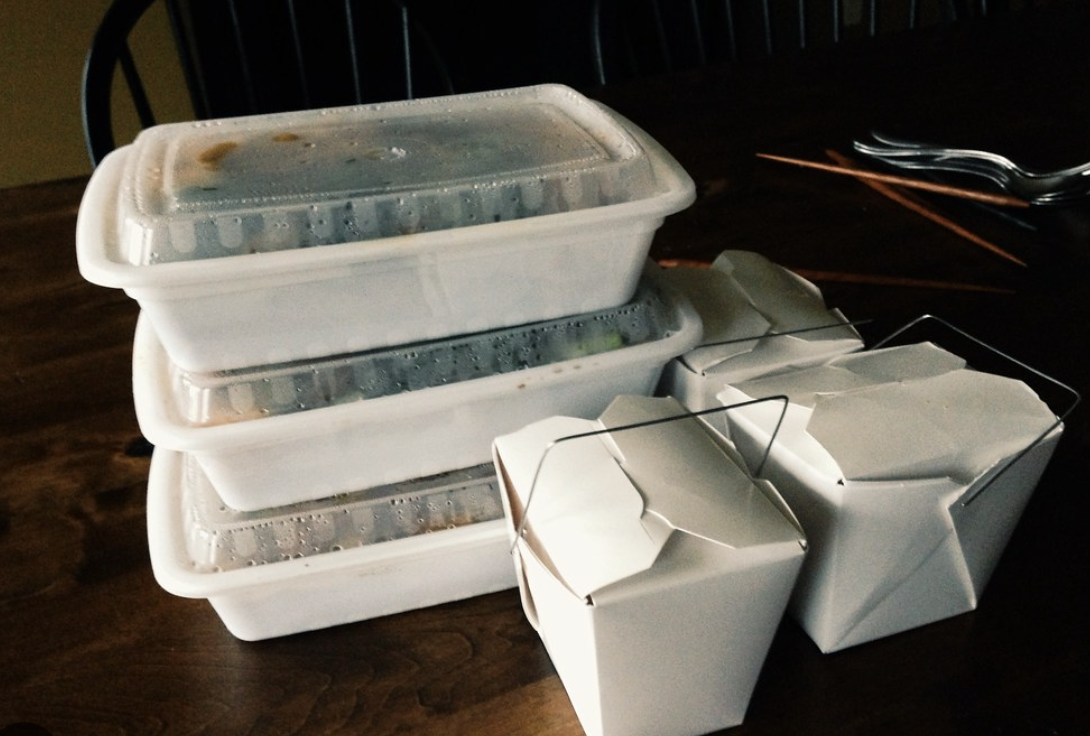

In [7]:
from IPython.display import Image
Image(filename='images/food.png') 

## Image Messages

In [8]:
import base64
# opens the image file in "read binary" mode
with open("images/food.png", "rb") as image_file:
    #reads the contents of the image as a bytes object
    binary_data = image_file.read() 
    #encodes the binary data using Base64 encoding
    base_64_encoded_data = base64.b64encode(binary_data) 
    #decodes base_64_encoded_data from bytes to a string
    base64_string = base_64_encoded_data.decode('utf-8')

In [9]:
base64_string[:100]

'iVBORw0KGgoAAAANSUhEUgAABEIAAALgCAYAAACQxtKmAAAMP2lDQ1BJQ0MgUHJvZmlsZQAASImVVwdYU8kWnltSIbQAAlJCb4KA'

In [10]:
messages = [
    {
        "role": "user",
        "content": [{
            "type": "image",
            "source": {
                "type": "base64",
                "media_type": "image/png",
                "data": base64_string
            },
        },
        {
            "type": "text",
            "text": """How many to-go containers of each type 
            are in this image?"""
        }]
    }
]

In [11]:
response = client.messages.create(
    messages=messages,
    model=MODEL_NAME,
    max_tokens=200
)
print(response.content[0].text)

Looking at the image, I can count:

**Rectangular plastic containers (with clear lids):** 3 stacked containers

**Chinese takeout boxes (folded paper with wire handles):** 2 boxes

So in total, there are 5 to-go containers - 3 plastic containers and 2 paper takeout boxes, along with what appears to be chopsticks and a fork on the table.


## Image Block Helper Function

In [12]:
import base64
import mimetypes

def create_image_message(image_path):
    # Open the image file in "read binary" mode
    with open(image_path, "rb") as image_file:
        # Read the contents of the image as a bytes object
        binary_data = image_file.read()
    # Encode the binary data using Base64 encoding
    base64_encoded_data = base64.b64encode(binary_data)
    # Decode base64_encoded_data from bytes to a string
    base64_string = base64_encoded_data.decode('utf-8')
    # Get the MIME type of the image based on its file extension
    mime_type, _ = mimetypes.guess_type(image_path)
    # Create the image block
    image_block = {
        "type": "image",
        "source": {
            "type": "base64",
            "media_type": mime_type,
            "data": base64_string
        }
    }
    
    
    return image_block

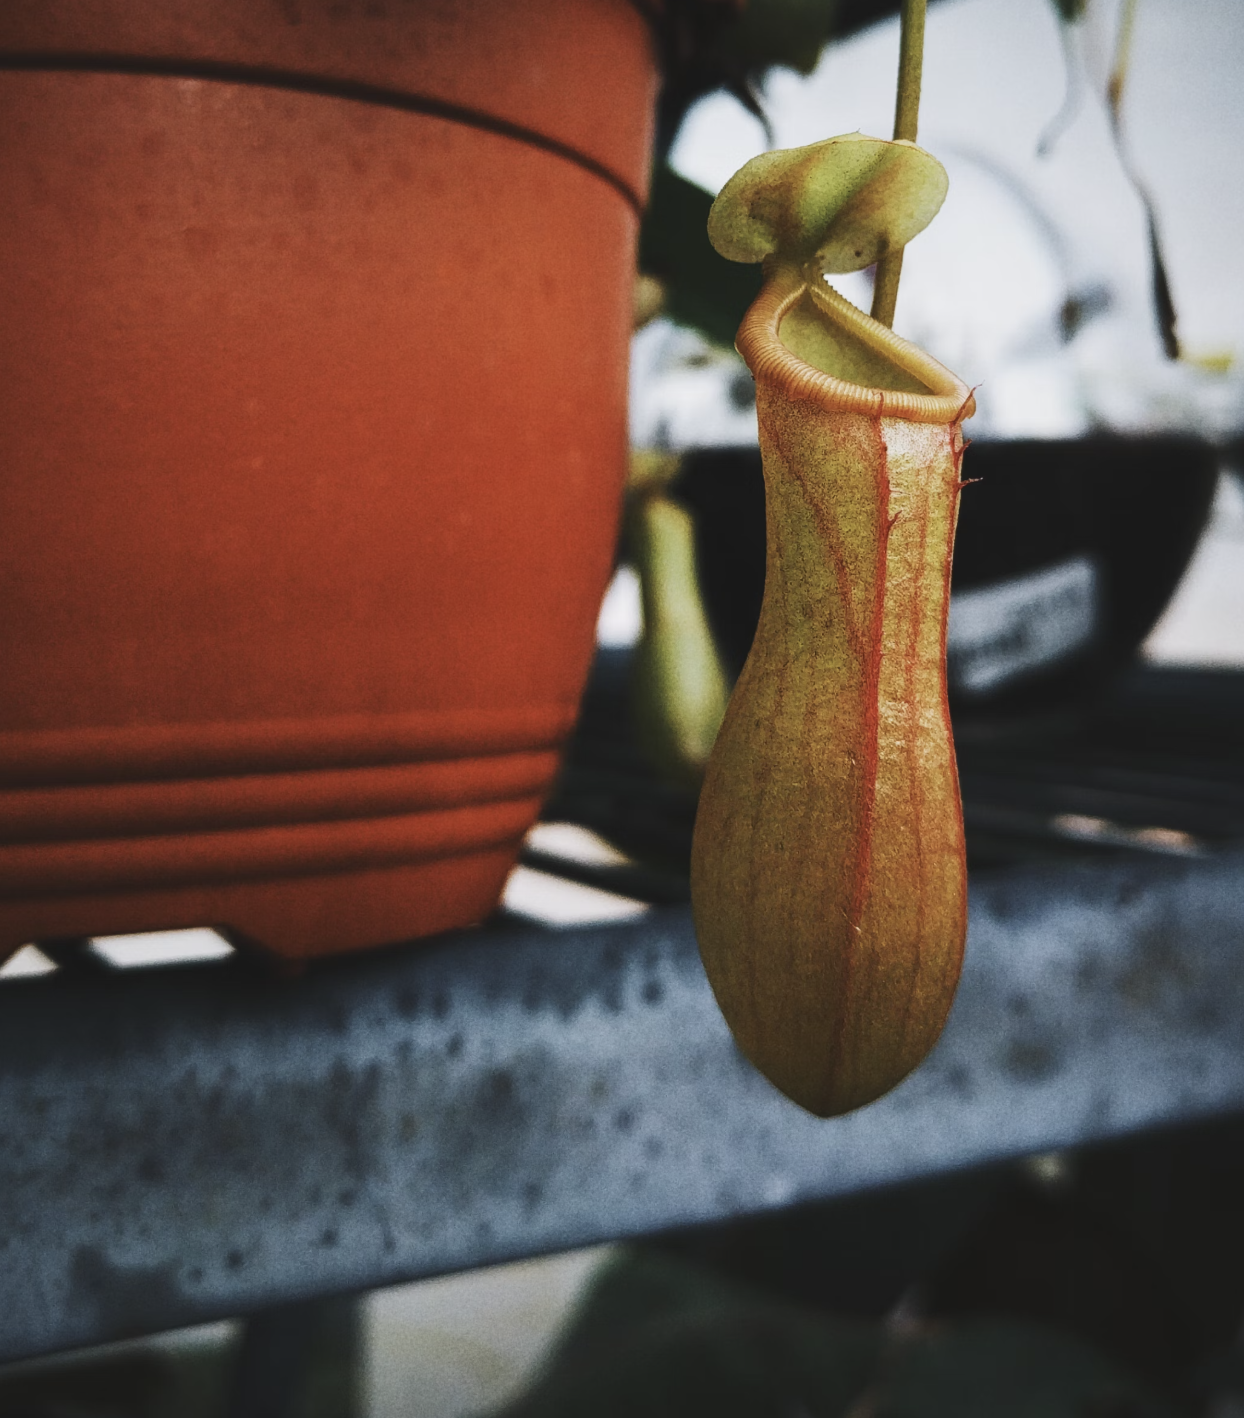

In [13]:
Image("images/plant.png")

In [14]:
messages = [
    {
        "role": "user",
        "content": [
            create_image_message("./images/plant.png"),
            {"type": "text", "text": "What species is this?"}
        ]
    }
]

response = client.messages.create(
    model=MODEL_NAME,
    max_tokens=2048,
    messages=messages
)
print(response.content[0].text)

This is a **Nepenthes** species, commonly known as a **tropical pitcher plant** or **monkey cup**. These are carnivorous plants that produce specialized leaf structures (the pitchers you see hanging) to trap and digest insects.

Based on the visible characteristics:
- The pale green/yellow coloring with reddish-maroon striping
- The peristome (the ribbed lip around the opening)
- The lid (operculum) structure
- The overall pitcher shape

This appears to be either a straight species like ***Nepenthes alata*** or ***Nepenthes ventricosa***, or more likely a **hybrid cultivar**, as many Nepenthes sold commercially are crosses bred for easier care and attractive pitcher coloring. Without seeing the full plant (leaves, growth habit) or knowing more about its origin, it's difficult to pinpoint the exact species/hybrid.

The plant is being grown in what looks like a nursery or greenhouse setting, based on the terracotta pots and metal shelving visible in the background.


## A Real World Use Case

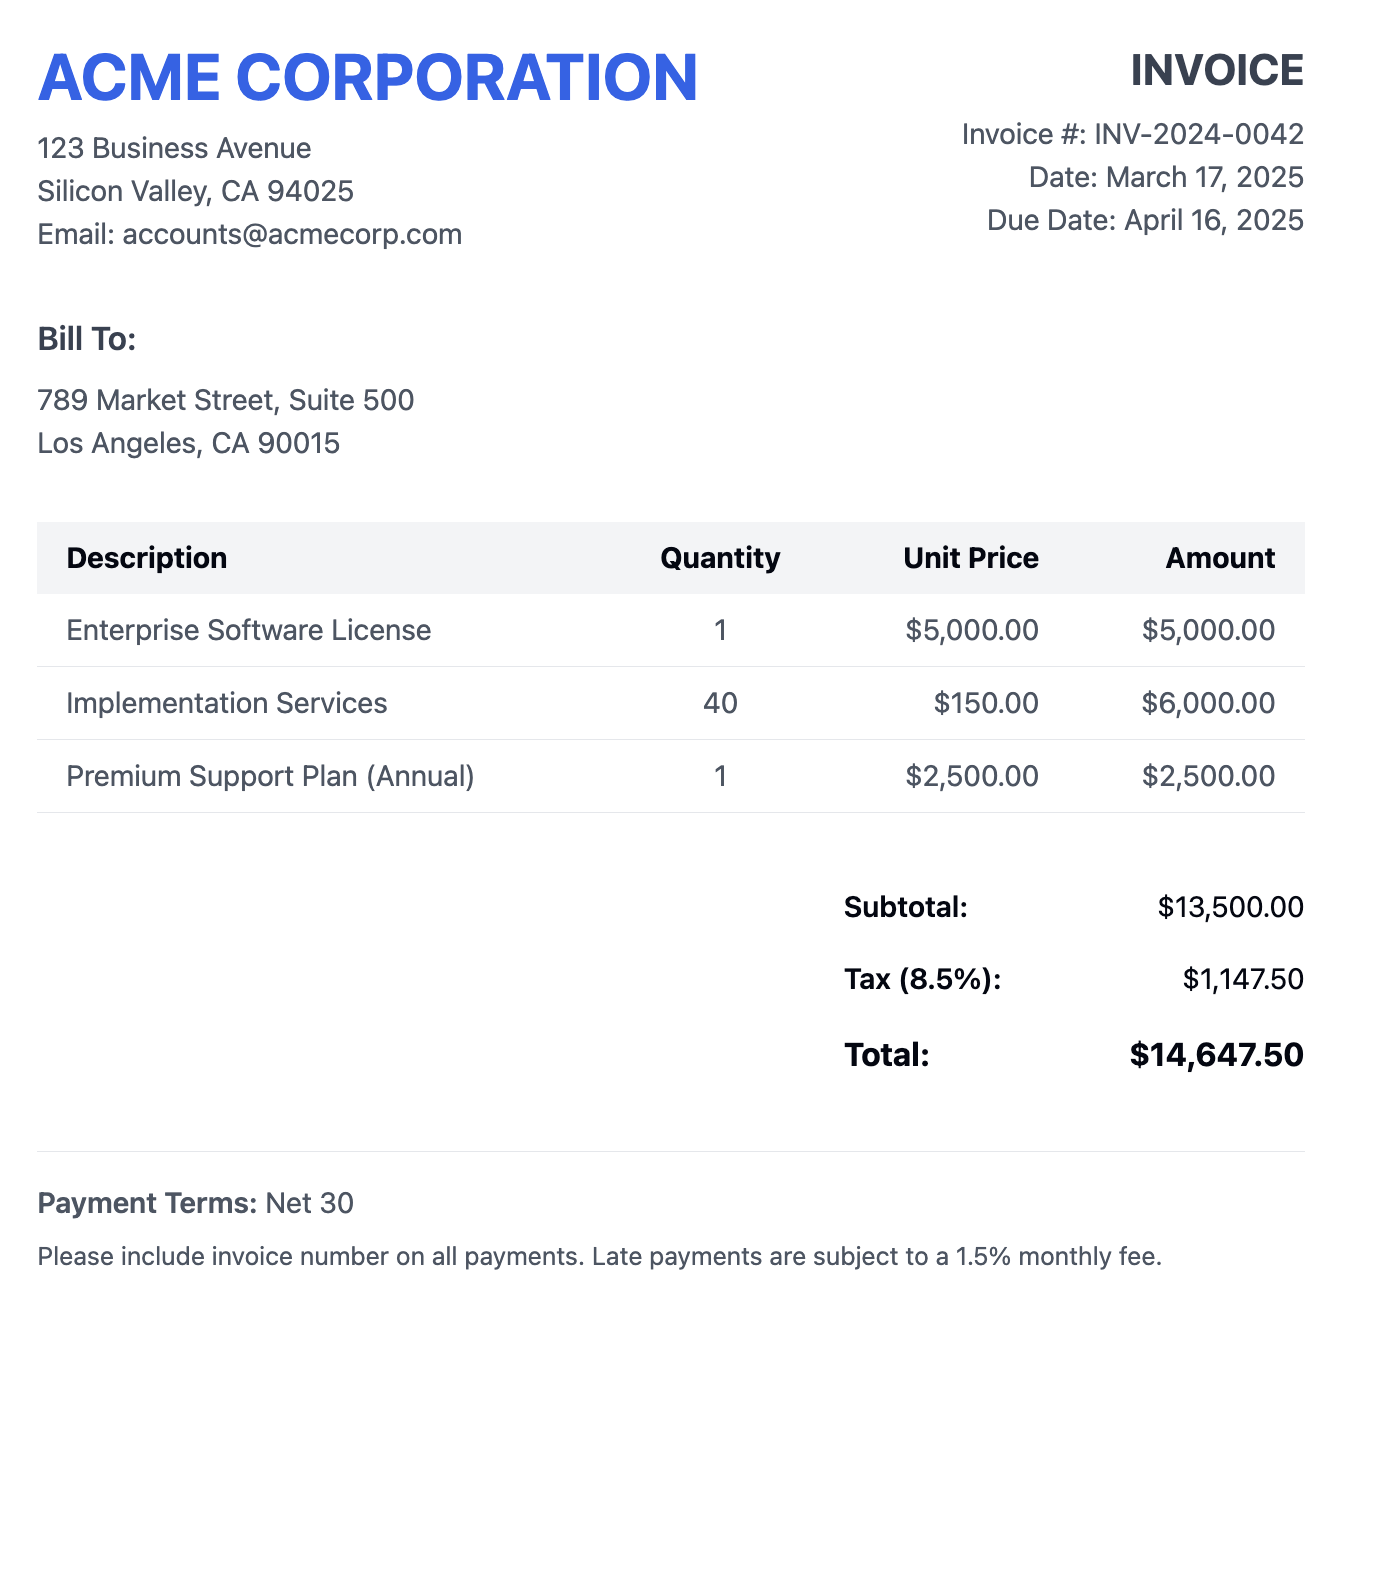

In [15]:
Image(filename='images/invoice.png') 

In [16]:
messages = [
    {
        "role": "user",
        "content": [
            create_image_message("./images/invoice.png"),
            {"type": "text", "text": """
                Generate a JSON object representing the contents
                of this invoice.  It should include all dates,
                dollar amounts, and addresses. 
                Only respond with the JSON itself.
            """
            }
        ]
    }
]

response = client.messages.create(
    model=MODEL_NAME,
    max_tokens=2048,
    messages=messages
)
print(response.content[0].text)

```json
{
  "invoice": {
    "company": {
      "name": "ACME CORPORATION",
      "address": {
        "street": "123 Business Avenue",
        "city": "Silicon Valley",
        "state": "CA",
        "zip": "94025"
      },
      "email": "accounts@acmecorp.com"
    },
    "invoiceNumber": "INV-2024-0042",
    "date": "March 17, 2025",
    "dueDate": "April 16, 2025",
    "billTo": {
      "address": {
        "street": "789 Market Street, Suite 500",
        "city": "Los Angeles",
        "state": "CA",
        "zip": "90015"
      }
    },
    "items": [
      {
        "description": "Enterprise Software License",
        "quantity": 1,
        "unitPrice": 5000.00,
        "amount": 5000.00
      },
      {
        "description": "Implementation Services",
        "quantity": 40,
        "unitPrice": 150.00,
        "amount": 6000.00
      },
      {
        "description": "Premium Support Plan (Annual)",
        "quantity": 1,
        "unitPrice": 2500.00,
        "amount": 2500.

## Streaming

In [17]:
response = client.messages.create(
    max_tokens=1024,
    messages=[{"role": "user", "content": "write a poem"}],
    model=MODEL_NAME,
)
print(response.content[0].text)

# Autumn's Quiet Return

The leaves let go without regret,
they trust the wind to carry them
somewhere beyond the branch's reach,
somewhere the roots cannot follow.

I used to think that falling meant
an ending, something lost or broken,
but now I see the tree stands bare
and waits, unbothered, for the spring.

There's wisdom in this yearly turn—
the way the world knows how to shed
what no longer serves the season,
how it trusts the dark to hold
what it cannot yet understand.

I want to learn this kind of letting go,
to drop what I've outgrown
like leaves upon an early frost,
and stand, unafraid, in winter's hush,
knowing green will come again.


In [18]:
with client.messages.stream(
    max_tokens=1024,
    messages=[{"role": "user", "content": "write a poem"}],
    model=MODEL_NAME,
) as stream:
  for text in stream.text_stream:
      print(text, end="", flush=True)

# Autumn Whispers

The leaves let go without a fight,
Drifting down through fading light,
Each one a small and quiet grace,
Falling into time and space.

The wind hums low, a gentle song,
Carrying summer's warmth along,
While trees stand bare against the sky,
Watching seasons wander by.

There's beauty in this letting go,
In colors bright before the snow,
A reminder, soft and true,
That endings hold their beauty too.

## Conclusion

## Extra Practice